In [34]:
#imports
from pathlib import Path
from rapidocr import RapidOCR
from rapidocr.utils.output import RapidOCROutput
import cv2
import matplotlib.pyplot as plt
import numpy as np

## Helper Functions

In [75]:
from dataclasses import dataclass


def find_repo_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for folder in (start, *start.parents):
        if (folder / ".git").exists():
            return folder
    raise FileNotFoundError(f"No git repo found above {start}")


REPO_ROOT = find_repo_root()

train_path = REPO_ROOT / "images" / "train"

@dataclass
class Sample:
    path: Path     
    img: np.ndarray  # BGR color


def load_images(folder: Path, limit: int | None = None) -> list[Sample]:
    samples = []

    for file_path in sorted(Path(folder).resolve().iterdir()):
        if not file_path.is_file():
            continue

        img = cv2.imread(str(file_path))
        if img is None or img.size == 0:
            continue

        try:
            rel_path = file_path.relative_to(REPO_ROOT)
        except ValueError:  # image lives outside the repo: keep the absolute path
            rel_path = file_path
        samples.append(Sample(rel_path, img))

        if limit is not None and len(samples) >= limit:
            break

    return samples

In [76]:
def visualize_results(results):
    for res in results:
        fig, row = plt.subplots(1, 2, figsize=(10, 10), layout="constrained",
                                gridspec_kw=dict(width_ratios=[1, 2]))  # vis() output is wider with teh results
        
        row[0].imshow(res["org_img"])
        row[0].set_title(res["name"])
        row[1].imshow(res["ocr_img"])
        row[1].set_title(f"RapidOCR - {res['name']}")

        row[0].set_axis_off()
        row[1].set_axis_off()
        plt.show()

In [80]:
samples = load_images(train_path, 3)

## 1 | RapidOCR

In [81]:
engine = RapidOCR()

def run_ocr(img: np.ndarray) -> RapidOCROutput | None:
    result = engine(img) 
    if not isinstance(result, RapidOCROutput) or result.boxes is None:
        return None
    return result

rapid_results = []

for sample in samples: 
    result = run_ocr(sample.img)
    org_img = cv2.cvtColor(sample.img, cv2.COLOR_BGR2RGB)  # cv2 loads BGR; matplotlib expects RGB

    if result is None: 
        continue

    vis_img = result.vis()  # BGR ndarray or None
    ocr_img = cv2.cvtColor(vis_img, cv2.COLOR_BGR2RGB) if vis_img is not None else org_img
    rapid_results.append(dict(
        name=str(sample.path),
        text=result.txts or (), 
        scores=result.scores or (), 
        org_img=org_img,
        ocr_img=ocr_img, 
    ))

[INFO] 2026-11-10 18:12:41,800 [RapidOCR] base.py:23: Using engine_name: onnxruntime
[INFO] 2026-11-10 18:12:41,823 [RapidOCR] download_file.py:60: File exists and is valid: /home/jmtcabili/Documents/DEV/TransacOCR/.venv/lib/python3.14/site-packages/rapidocr/models/PP-OCRv6_det_small.onnx
[INFO] 2026-11-10 18:12:41,823 [RapidOCR] main.py:63: Using /home/jmtcabili/Documents/DEV/TransacOCR/.venv/lib/python3.14/site-packages/rapidocr/models/PP-OCRv6_det_small.onnx


[INFO] 2026-11-10 18:12:42,295 [RapidOCR] base.py:23: Using engine_name: onnxruntime
[INFO] 2026-11-10 18:12:42,298 [RapidOCR] download_file.py:60: File exists and is valid: /home/jmtcabili/Documents/DEV/TransacOCR/.venv/lib/python3.14/site-packages/rapidocr/models/ch_ppocr_mobile_v2.0_cls_mobile.onnx
[INFO] 2026-11-10 18:12:42,298 [RapidOCR] main.py:63: Using /home/jmtcabili/Documents/DEV/TransacOCR/.venv/lib/python3.14/site-packages/rapidocr/models/ch_ppocr_mobile_v2.0_cls_mobile.onnx
[INFO] 2026-11-10 18:12:42,383 [RapidOCR] base.py:23: Using engine_name: onnxruntime
[INFO] 2026-11-10 18:12:42,429 [RapidOCR] download_file.py:60: File exists and is valid: /home/jmtcabili/Documents/DEV/TransacOCR/.venv/lib/python3.14/site-packages/rapidocr/models/PP-OCRv6_rec_small.onnx
[INFO] 2026-11-10 18:12:42,430 [RapidOCR] main.py:63: Using /home/jmtcabili/Documents/DEV/TransacOCR/.venv/lib/python3.14/site-packages/rapidocr/models/PP-OCRv6_rec_small.onnx
[INFO] 2026-11-10 18:12:42,973 [RapidOCR] 

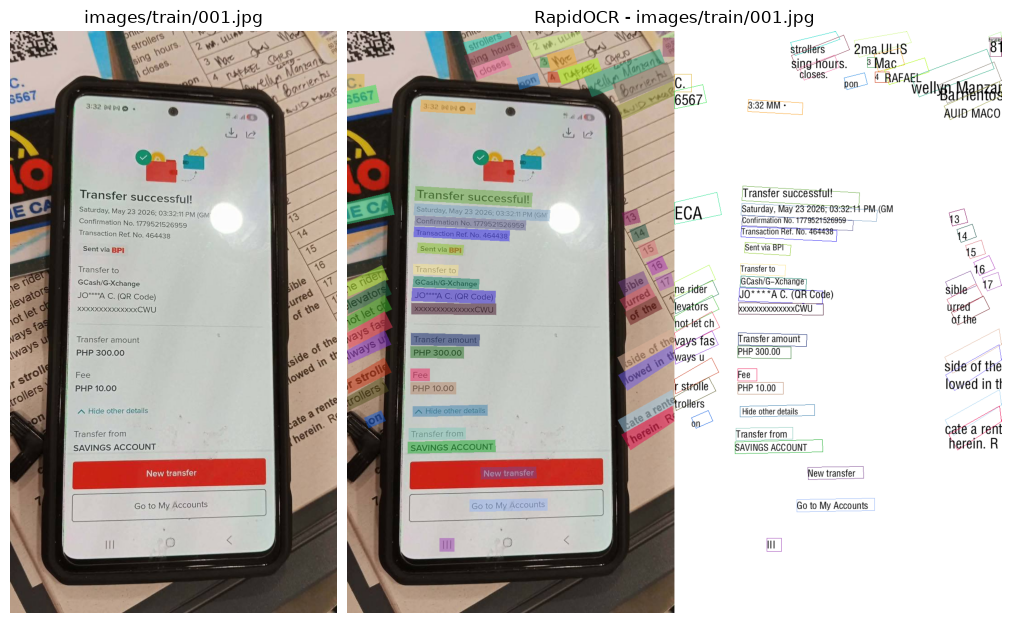

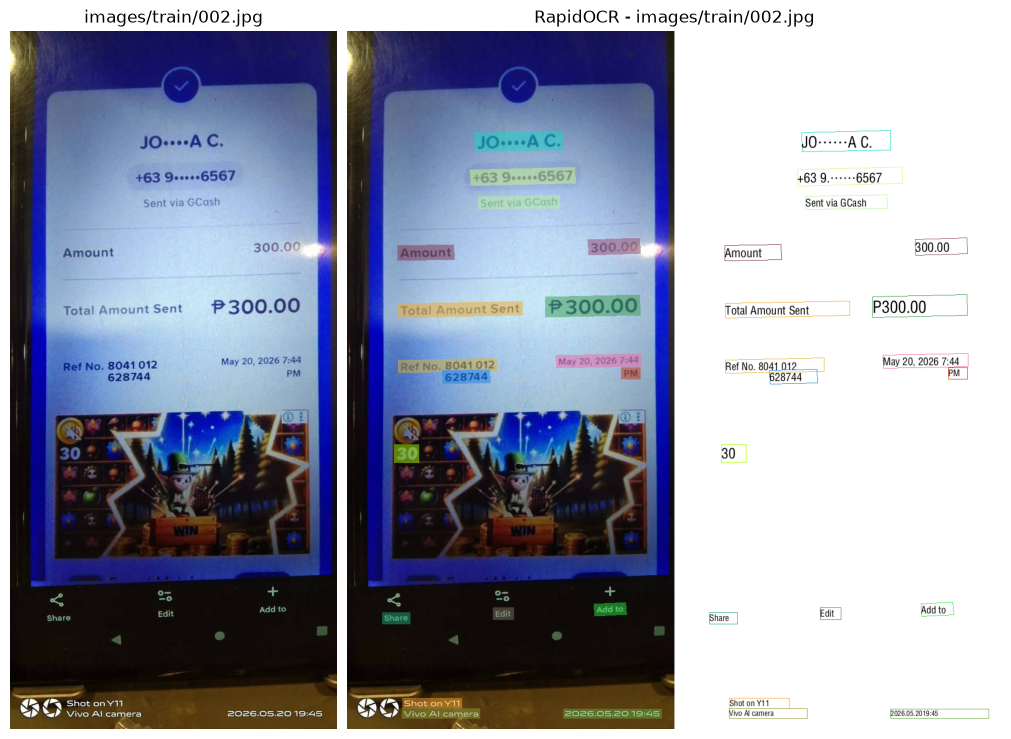

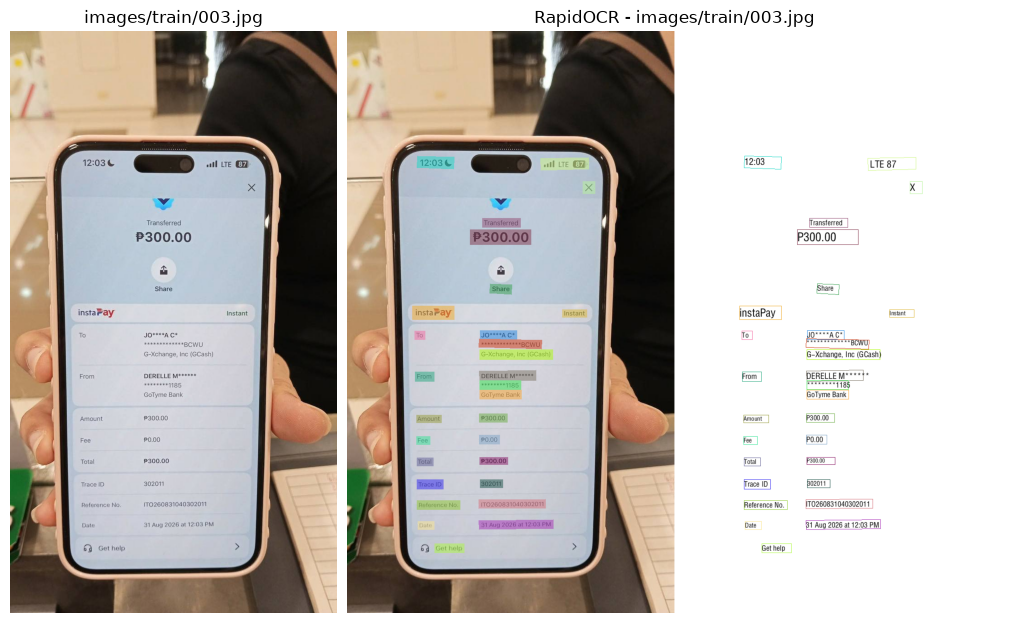

In [79]:
#For each pair of images and their results, I want a 1x2 subplot with the results printed below
visualize_results(rapid_results)

## 2 | PyTesseract

In [61]:
!pip install pytesseract

In [85]:
import pandas as pd
import pytesseract
pd.set_option("display.max_colwidth", None)
tesseract_rows = []
for sample in samples:
    rgb = cv2.cvtColor(sample.img, cv2.COLOR_BGR2RGB)  # pytesseract reads ndarrays as RGB
    tesseract_rows.append({
        "filename": sample.path.name,
        "extracted_text": pytesseract.image_to_string(rgb).strip(),
    })

tesseract_df = pd.DataFrame(tesseract_rows, columns=["filename", "extracted_text"])
tesseract_df

,filename,extracted_text
0,001.jpg,"332 MM @ +\n\nTransfer successful!\n\nSaturday, May 23 2026; 03:32:11 pM (Gn\nConfirmation No. 1779521526959\nTransaction Ref, No. 464438\n\nSent via BP\n\nTransfer to\nGCash/G-Xchange\nJOA C. (QR Code)\nXXOOOOAKXXXXCWU,\n\nTransfer amount\nPHP 300.00\n\nee\nPHP 10.00\n\n/ Hide other details\n\nTransfer from\nSAVINGS ACCOUNT\n\nGo to My Accounts"
1,002.jpg,463 Qee00+6567\n\nAmount\n\nRef No. 8041 012\n628744\n\n< %e\nsar}\nae Add to\n\nShare\n\nry\n\nBi\nJ ¢ } Shot on Y11\n“a? VivoAl camera 2026.05.20 19:45\neye
2,003.jpg,"Transferred\n\nP300.00\n\nInstant\n\no JOR Ce\nScoarnninces Be\nG-Xchange, Inc (GCash)\n\nDERELLE M******\n. +1185\n\nGoTyme Bank\n\n300.00\n\nAmount\n\nTotal 300.00\n\n302011\n\n179260831040302011\n\nReference No\n\n31 Aug 2026 at 12:03 PM"


## 3 | PaddleOCR

In [ ]:
# Verify that PaddleOCR is installed successfully
import paddleocr
print(f"PaddleOCR version: {paddleocr.__version__}")

# If you use the local paddle_static inference engine, you can further verify PaddlePaddle and GPU availability
import paddle
print(f"Paddle version: {paddle.__version__}")
print(f"GPU available: {paddle.is_compiled_with_cuda()}")
print(f"GPU count: {paddle.device.cuda.device_count()}")

PaddleOCR version: 3.7.0


ModuleNotFoundError: No module named 'paddle'